In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

from collections import defaultdict

# Reproducibility
np.random.seed(42)
random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [45]:
class TicTacToeEnv:

    def __init__(self):
        self.board = None
        self.reset()

    def reset(self):

        self.board = np.zeros(9, dtype=int)

        return tuple(self.board)

    def available_actions(self):

        return [
            i for i in range(9)
            if self.board[i] == 0
        ]

    def check_winner(self, player):

        winning_combinations = [
            (0, 1, 2),
            (3, 4, 5),
            (6, 7, 8),

            (0, 3, 6),
            (1, 4, 7),
            (2, 5, 8),

            (0, 4, 8),
            (2, 4, 6)
        ]

        for combination in winning_combinations:

            if all(
                self.board[position] == player
                for position in combination
            ):
                return True

        return False

    def step(self, action, player):

        if action not in self.available_actions():
            raise ValueError("Invalid move!")

        self.board[action] = player

        # Reward is measured from the RL agent's perspective.
        if self.check_winner(1):
            return tuple(self.board), 1, True

        if self.check_winner(-1):
            return tuple(self.board), -1, True

        if len(self.available_actions()) == 0:
            return tuple(self.board), 0, True

        return tuple(self.board), 0, False

    def render(self):

        symbols = {
            1: "X",
            -1: "O",
            0: " "
        }

        print("\n")

        for row in range(3):

            cells = [
                symbols[self.board[row * 3 + col]]
                for col in range(3)
            ]

            print(" | ".join(cells))

            if row < 2:
                print("---------")

        print("\n")

In [46]:
env = TicTacToeEnv()

print("Initial Tic-Tac-Toe Board")

env.render()

print("Available Actions:", env.available_actions())

# Test one move
next_state, reward, done = env.step(0, 1)

print("After Agent Plays Position 0")

env.render()

print("Reward:", reward)
print("Game Finished:", done)

Initial Tic-Tac-Toe Board


  |   |  
---------
  |   |  
---------
  |   |  


Available Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8]
After Agent Plays Position 0


X |   |  
---------
  |   |  
---------
  |   |  


Reward: 0
Game Finished: False


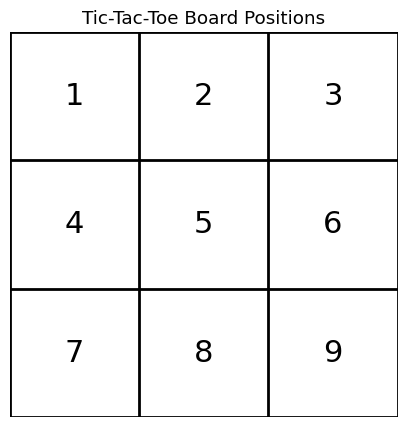

In [47]:
plt.figure(figsize=(5, 5))

for i in range(10):

    plt.axhline(i // 3, color='black', linewidth=2) if i % 3 == 0 else None

for i in range(4):

    plt.axvline(i, color='black', linewidth=2)

for i in range(9):

    row = i // 3
    col = i % 3

    plt.text(
        col + 0.5,
        row + 0.5,
        str(i + 1),
        ha='center',
        va='center',
        fontsize=22
    )

plt.xlim(0, 3)
plt.ylim(3, 0)

plt.title("Tic-Tac-Toe Board Positions")

plt.axis('off')
plt.show()

In [48]:
# Q-learning parameters

learning_rate = 0.2

discount_factor = 0.95

epsilon = 1.0

epsilon_min = 0.05

epsilon_decay = 0.9999

episodes = 50000

# Q-table
Q = {}

print("Q-Learning Parameters")

print("Learning Rate:", learning_rate)
print("Discount Factor:", discount_factor)
print("Initial Epsilon:", epsilon)
print("Minimum Epsilon:", epsilon_min)
print("Training Episodes:", episodes)

Q-Learning Parameters
Learning Rate: 0.2
Discount Factor: 0.95
Initial Epsilon: 1.0
Minimum Epsilon: 0.05
Training Episodes: 50000


In [49]:
def get_q_values(state):

    if state not in Q:

        Q[state] = np.zeros(9)

    return Q[state]


def choose_action(state, available_actions, epsilon):

    # Exploration
    if random.random() < epsilon:

        return random.choice(available_actions)

    # Exploitation
    q_values = get_q_values(state)

    valid_q_values = {
        action: q_values[action]
        for action in available_actions
    }

    max_value = max(valid_q_values.values())

    best_actions = [
        action
        for action, value in valid_q_values.items()
        if value == max_value
    ]

    return random.choice(best_actions)


print("Q-Table initialized successfully!")

Q-Table initialized successfully!


In [50]:
env = TicTacToeEnv()

training_results = []

epsilon = 1.0

for episode in range(episodes):

    state = env.reset()

    done = False

    while not done:

        # Agent selects an action
        available = env.available_actions()

        action = choose_action(
            state,
            available,
            epsilon
        )

        # Agent makes its move
        next_state, reward, done = env.step(action, 1)

        # Random opponent responds if game is not over
        if not done:

            opponent_action = random.choice(
                env.available_actions()
            )

            next_state, reward, done = env.step(
                opponent_action,
                -1
            )

        # Q-learning update
        current_q = get_q_values(state)

        if done:

            target = reward

        else:

            next_actions = env.available_actions()

            next_q_values = get_q_values(next_state)

            target = reward + discount_factor * max(
                next_q_values[a]
                for a in next_actions
            )

        current_q[action] += learning_rate * (
            target - current_q[action]
        )

        state = next_state

    # Record final game result
    training_results.append(reward)

    # Reduce exploration gradually
    epsilon = max(
        epsilon_min,
        epsilon * epsilon_decay
    )

    if (episode + 1) % 5000 == 0:

        print(
            f"Episode: {episode + 1}/{episodes} | "
            f"Epsilon: {epsilon:.4f}"
        )

print("\nTraining Completed!")
print("Total Q-Table States:", len(Q))

Episode: 5000/50000 | Epsilon: 0.6065
Episode: 10000/50000 | Epsilon: 0.3679
Episode: 15000/50000 | Epsilon: 0.2231
Episode: 20000/50000 | Epsilon: 0.1353
Episode: 25000/50000 | Epsilon: 0.0821
Episode: 30000/50000 | Epsilon: 0.0500
Episode: 35000/50000 | Epsilon: 0.0500
Episode: 40000/50000 | Epsilon: 0.0500
Episode: 45000/50000 | Epsilon: 0.0500
Episode: 50000/50000 | Epsilon: 0.0500

Training Completed!
Total Q-Table States: 2386


In [51]:
results = np.array(training_results)

window_size = 1000

rolling_rewards = pd.Series(results).rolling(
    window=window_size
).mean()

rolling_win_rate = pd.Series(
    (results == 1).astype(float)
).rolling(window=window_size).mean() * 100

rolling_loss_rate = pd.Series(
    (results == -1).astype(float)
).rolling(window=window_size).mean() * 100

rolling_draw_rate = pd.Series(
    (results == 0).astype(float)
).rolling(window=window_size).mean() * 100

print("Training Results")

print("Total Episodes:", episodes)

print("Training Win Rate:",
      round(np.mean(results == 1) * 100, 2), "%")

print("Training Draw Rate:",
      round(np.mean(results == 0) * 100, 2), "%")

print("Training Loss Rate:",
      round(np.mean(results == -1) * 100, 2), "%")

Training Results
Total Episodes: 50000
Training Win Rate: 90.93 %
Training Draw Rate: 3.62 %
Training Loss Rate: 5.45 %


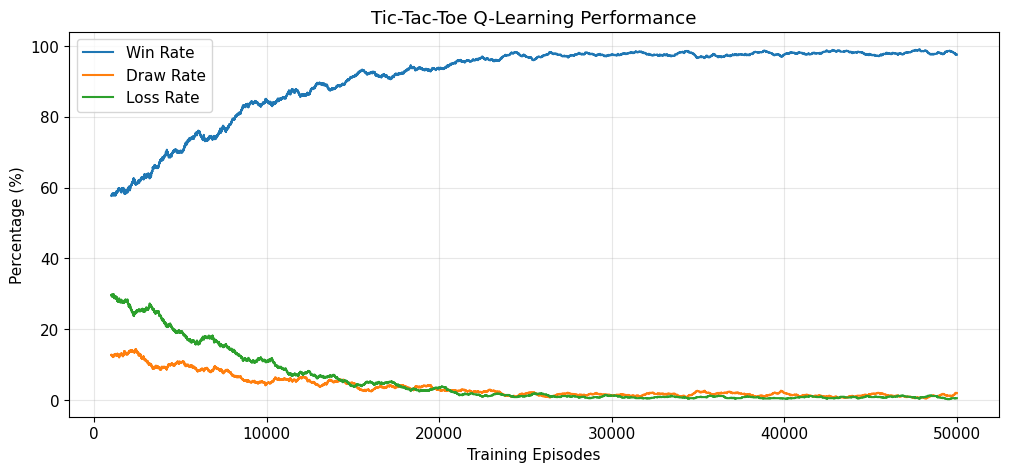

In [52]:
plt.figure(figsize=(12, 5))

plt.plot(
    rolling_win_rate,
    label="Win Rate"
)

plt.plot(
    rolling_draw_rate,
    label="Draw Rate"
)

plt.plot(
    rolling_loss_rate,
    label="Loss Rate"
)

plt.xlabel("Training Episodes")

plt.ylabel("Percentage (%)")

plt.title("Tic-Tac-Toe Q-Learning Performance")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [53]:
def greedy_action(state, available_actions):

    q_values = get_q_values(state)

    values = [
        q_values[action]
        for action in available_actions
    ]

    max_value = max(values)

    best_actions = [
        action
        for action in available_actions
        if q_values[action] == max_value
    ]

    return random.choice(best_actions)

In [54]:
def evaluate_agent(number_of_games=5000):

    wins = 0
    losses = 0
    draws = 0

    for game in range(number_of_games):

        env = TicTacToeEnv()

        done = False

        while not done:

            # RL agent plays X
            state = tuple(env.board)

            action = greedy_action(
                state,
                env.available_actions()
            )

            next_state, reward, done = env.step(
                action,
                1
            )

            if done:
                break

            # Random opponent plays O
            opponent_action = random.choice(
                env.available_actions()
            )

            next_state, reward, done = env.step(
                opponent_action,
                -1
            )

        if reward == 1:
            wins += 1

        elif reward == -1:
            losses += 1

        else:
            draws += 1

    return wins, losses, draws


wins, losses, draws = evaluate_agent(5000)

total_games = wins + losses + draws

print("Evaluation Results")

print("Total Games:", total_games)

print("Wins:", wins)
print("Losses:", losses)
print("Draws:", draws)

print("Win Rate:", round(wins / total_games * 100, 2), "%")

print("Loss Rate:", round(losses / total_games * 100, 2), "%")

print("Draw Rate:", round(draws / total_games * 100, 2), "%")

Evaluation Results
Total Games: 5000
Wins: 4916
Losses: 7
Draws: 77
Win Rate: 98.32 %
Loss Rate: 0.14 %
Draw Rate: 1.54 %


In [55]:
def evaluate_random_agents(number_of_games=5000):

    wins = 0
    losses = 0
    draws = 0

    for _ in range(number_of_games):

        env = TicTacToeEnv()

        done = False

        while not done:

            # Random X
            action_x = random.choice(
                env.available_actions()
            )

            _, reward, done = env.step(action_x, 1)

            if done:
                break

            # Random O
            action_o = random.choice(
                env.available_actions()
            )

            _, reward, done = env.step(action_o, -1)

        if reward == 1:
            wins += 1

        elif reward == -1:
            losses += 1

        else:
            draws += 1

    return wins, losses, draws


random_wins, random_losses, random_draws = (
    evaluate_random_agents(5000)
)

comparison = pd.DataFrame({

    "Metric": [
        "Win Rate",
        "Loss Rate",
        "Draw Rate"
    ],

    "Random vs Random": [
        random_wins / 5000 * 100,
        random_losses / 5000 * 100,
        random_draws / 5000 * 100
    ],

    "Trained RL vs Random": [
        wins / total_games * 100,
        losses / total_games * 100,
        draws / total_games * 100
    ]

})

display(comparison.round(2))

,Metric,Random vs Random,Trained RL vs Random
0,Win Rate,59.16,98.32
1,Loss Rate,28.36,0.14
2,Draw Rate,12.48,1.54


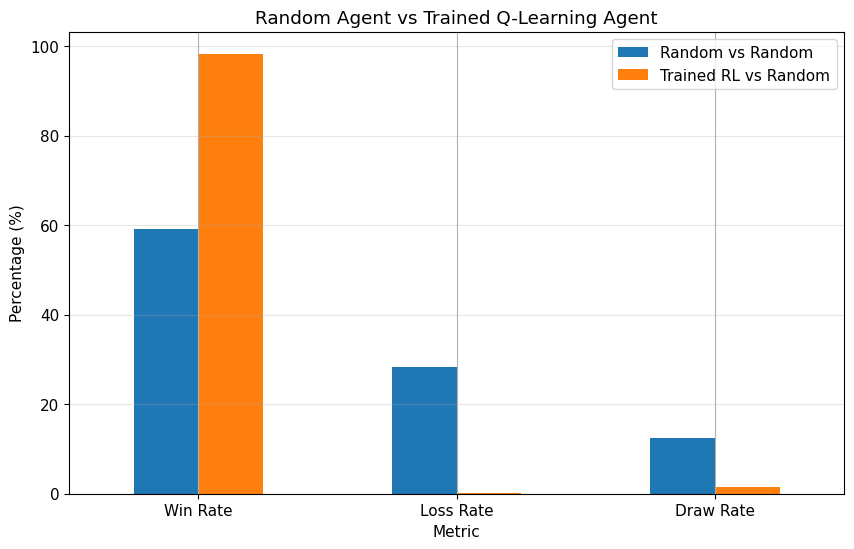

In [56]:
comparison_plot = comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Percentage (%)")

plt.title("Random Agent vs Trained Q-Learning Agent")

plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.legend()

plt.show()

In [57]:
def demonstrate_game():

    env = TicTacToeEnv()

    done = False

    move_number = 1

    print("Trained RL Agent (X) vs Random Opponent (O)")

    env.render()

    while not done:

        # RL agent's turn
        state = tuple(env.board)

        action = greedy_action(
            state,
            env.available_actions()
        )

        print(f"Agent chooses position {action + 1}")

        _, reward, done = env.step(action, 1)

        env.render()

        if done:
            break

        # Opponent's turn
        opponent_action = random.choice(
            env.available_actions()
        )

        print(
            f"Random opponent chooses position "
            f"{opponent_action + 1}"
        )

        _, reward, done = env.step(
            opponent_action,
            -1
        )

        env.render()

        move_number += 1

    if reward == 1:
        print("Result: Reinforcement Learning Agent Wins!")

    elif reward == -1:
        print("Result: Random Opponent Wins!")

    else:
        print("Result: Draw!")


demonstrate_game()

Trained RL Agent (X) vs Random Opponent (O)


  |   |  
---------
  |   |  
---------
  |   |  


Agent chooses position 7


  |   |  
---------
  |   |  
---------
X |   |  


Random opponent chooses position 8


  |   |  
---------
  |   |  
---------
X | O |  


Agent chooses position 1


X |   |  
---------
  |   |  
---------
X | O |  


Random opponent chooses position 6


X |   |  
---------
  |   | O
---------
X | O |  


Agent chooses position 4


X |   |  
---------
X |   | O
---------
X | O |  


Result: Reinforcement Learning Agent Wins!


In [58]:
def play_against_ai():

    env = TicTacToeEnv()

    done = False

    print("You are O. The AI is X.")

    print("Choose positions between 1 and 9.")

    while not done:

        # AI turn
        state = tuple(env.board)

        ai_action = greedy_action(
            state,
            env.available_actions()
        )

        env.step(ai_action, 1)

        print("\nAI played:")

        env.render()

        if env.check_winner(1):
            print("AI Wins!")
            break

        if not env.available_actions():
            print("Draw!")
            break

        # Human turn
        while True:

            try:

                human_action = int(
                    input("Enter your position (1-9): ")
                ) - 1

                if human_action in env.available_actions():
                    break

                print("Invalid or occupied position.")

            except ValueError:

                print("Enter a number between 1 and 9.")

        env.step(human_action, -1)

        print("\nYour move:")

        env.render()

        if env.check_winner(-1):
            print("You Win!")
            break

        if not env.available_actions():
            print("Draw!")
            break


# Uncomment this line to play:
# play_against_ai()